# Stream A — Results Summary

Aggregates all Stream A outputs (NER → Visual Grounding → Entity Scorer) into
paper-ready results tables and figures.

**What we evaluate:**
- Stream A classification performance (threshold + logistic regression on entity features)
- Comparison vs naive CLIP baseline
- Feature correlation heatmap
- Error analysis — what does Stream A get wrong?
- Paper-ready consolidated results table

**Outputs:**
- `paper/tables/stream_a_results.csv`
- `paper/tables/stream_a_vs_baseline.csv`
- `paper/figures/stream_a_feature_heatmap.png`
- `paper/figures/stream_a_confusion.png`
- `paper/figures/stream_a_summary_bar.png`
- `paper/figures/stream_a_roc.png`

**Order:** `entity_scorer` → **`stream_a_results`** → `03_stream_b/clip_features`

## 1. Environment

In [1]:
import sys, pickle
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    roc_auc_score, accuracy_score, f1_score,
    precision_score, recall_score, confusion_matrix, roc_curve
)
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

sys.path.insert(0, str(Path("../../").resolve()))
from src.utils.paths import *
from src.utils.io import load_json

sns.set_theme(style="whitegrid", font_scale=1.1)

# ── Colour palette (distinct, no overlapping issue) ─────────────────────────
C_OOC     = "#E05A4B"   # red
C_GENUINE = "#4B8AE0"   # blue
C_BAR1    = "#4B8AE0"
C_BAR2    = "#F0A500"
C_BAR3    = "#2ECC71"

FEAT_CACHE   = CACHE / "entity_scorer"
PAPER_FIGS   = ROOT  / "paper" / "figures"
PAPER_TABLES = ROOT  / "paper" / "tables"
for d in [PAPER_FIGS, PAPER_TABLES]:
    d.mkdir(parents=True, exist_ok=True)

def savefig(name):
    p = PAPER_FIGS / f"{name}.png"
    plt.savefig(p, bbox_inches="tight", dpi=150)
    print(f"  Saved → {p.relative_to(ROOT)}")

def savecsv(df, name):
    p = PAPER_TABLES / f"{name}.csv"
    df.to_csv(p, index=False)
    print(f"  Saved → {p.relative_to(ROOT)}")

# Histogram helper: step style to avoid overlap
def plot_hist_pair(ax, ooc_vals, gen_vals, xlabel, title):
    lo = min(ooc_vals.min(), gen_vals.min())
    hi = max(ooc_vals.max(), gen_vals.max())
    bins = np.linspace(lo, hi, 45) if hi > lo else 10
    ax.hist(gen_vals, bins=bins, alpha=0.55, color=C_GENUINE,
            label=f"Genuine μ={gen_vals.mean():.3f}")
    ax.hist(ooc_vals, bins=bins, histtype="step", linewidth=2.0,
            color=C_OOC, label=f"OOC μ={ooc_vals.mean():.3f}")
    ax.set_title(title, fontweight="bold")
    ax.set_xlabel(xlabel)
    ax.legend(fontsize=9)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

print("Setup done.")

Setup done.


## 2. Load features and labels

In [2]:
all_feats = pickle.load(open(FEAT_CACHE / "features_all.pkl", "rb"))

def bin_label(v):
    return 1 if str(v).strip().lower() in ("1", "true", "out-of-context") else 0

verite_df = pd.read_csv(VERITE / "VERITE.csv")
verite_df["label"] = verite_df["label"].apply(bin_label)
verite_labels = {f"verite_{i}": int(r["label"]) for i, r in verite_df.iterrows()}

raw = load_json(DATA / "mmfakebench" / "MMFakeBench_test.json")
mm_pairs = raw if isinstance(raw, list) else list(raw.values())
mmfake_labels = {f"mmfake_{i}": int(str(p.get("gt_answers","")).lower() == "fake")
                 for i, p in enumerate(mm_pairs)}

nc_labels = {}
for split in ["train", "val", "test"]:
    raw2 = load_json(NEWSCLIP / f"{split}.json")
    pairs = raw2.get("annotations", raw2) if isinstance(raw2, dict) else raw2
    for row in pairs:
        nc_labels[str(row["id"])] = int(row["falsified"])

rows = []
for pid, feats in all_feats.items():
    if pid.startswith("verite_"):
        ds, lbl = "verite", verite_labels.get(pid, -1)
    elif pid.startswith("mmfake_"):
        ds, lbl = "mmfake", mmfake_labels.get(pid, -1)
    else:
        ds, lbl = "newsclippings", nc_labels.get(pid, -1)
    rows.append({"pid": pid, "dataset": ds, "label": lbl, **feats})

df = pd.DataFrame(rows)
df = df[df["label"] >= 0]
print(f"  Total labelled pairs: {len(df):,}")
for ds, sub in df.groupby("dataset"):
    print(f"    {ds:<15}: {len(sub):,}  OOC={sub['label'].mean()*100:.1f}%")

  Total labelled pairs: 53,681
    mmfake         : 10,000  OOC=70.0%
    newsclippings  : 42,680  OOC=100.0%
    verite         : 1,001  OOC=66.2%


## 3. Evaluation helpers

In [3]:
feature_names = ["n_entities", "max_grounding", "min_grounding", "mean_grounding",
                 "person_max", "gpe_max", "org_max", "clip_sim"]

def evaluate(y_true, y_pred, y_score=None):
    m = {
        "acc":  round(accuracy_score(y_true, y_pred)*100, 2),
        "f1":   round(f1_score(y_true, y_pred, zero_division=0)*100, 2),
        "prec": round(precision_score(y_true, y_pred, zero_division=0)*100, 2),
        "rec":  round(recall_score(y_true, y_pred, zero_division=0)*100, 2),
    }
    if y_score is not None and len(np.unique(y_true)) == 2:
        try:
            m["auroc"] = round(roc_auc_score(y_true, y_score)*100, 2)
        except Exception:
            m["auroc"] = np.nan
    return m

def best_threshold_predict(y_true, scores, higher_is_ooc=False, n=300):
    """Find threshold on scores maximising accuracy. Returns predictions + threshold."""
    ts = np.linspace(scores.min(), scores.max(), n)
    best_acc, best_t = 0, ts[0]
    for t in ts:
        pred = (scores >= t).astype(int) if higher_is_ooc else (scores < t).astype(int)
        acc = (pred == y_true).mean()
        if acc > best_acc: best_acc, best_t = acc, t
    pred = (scores >= best_t).astype(int) if higher_is_ooc else (scores < best_t).astype(int)
    return pred, best_t

print("Helpers ready.")

Helpers ready.


## 4. VERITE — full evaluation

In [4]:
v = df[df["dataset"] == "verite"].copy().reset_index(drop=True)
y_v = v["label"].values
verite_results = []

# ── Majority baseline ──
majority = int(y_v.mean() > 0.5)
verite_results.append({"method": "majority_class", "dataset": "verite",
                        **evaluate(y_v, np.full_like(y_v, majority))})

# ── CLIP similarity threshold ──
clip_s = v["clip_sim"].fillna(v["clip_sim"].median()).values
pred_clip, t_clip = best_threshold_predict(y_v, clip_s, higher_is_ooc=False)
m = evaluate(y_v, pred_clip, -clip_s)  # negate: lower clip_sim = more OOC
verite_results.append({"method": "clip_sim_threshold", "dataset": "verite", **m})
print(f"  VERITE clip_sim threshold={t_clip:.3f}  acc={m['acc']}%  auroc={m.get('auroc')}%")

# ── Best single entity feature ──
for f in ["person_max", "max_grounding", "min_grounding"]:
    s = v[f].fillna(v[f].median()).values
    pred_f, t_f = best_threshold_predict(y_v, s, higher_is_ooc=False)
    m = evaluate(y_v, pred_f, -s)
    verite_results.append({"method": f"threshold_{f}", "dataset": "verite", **m})
    print(f"  VERITE {f:<18} threshold={t_f:.3f}  acc={m['acc']}%  auroc={m.get('auroc')}%")

# ── Logistic regression on all features (80/20 within VERITE) ──
feat_cols = [f for f in feature_names if v[f].notna().sum() > 50]
X_v = v[feat_cols].fillna(0).values
idx = np.random.RandomState(42).permutation(len(X_v))
tr, te = idx[:int(0.8*len(idx))], idx[int(0.8*len(idx)):]
pipe = Pipeline([("sc", StandardScaler()), ("lr", LogisticRegression(max_iter=500, C=1.0))])
pipe.fit(X_v[tr], y_v[tr])
pred_lr = pipe.predict(X_v[te])
prob_lr = pipe.predict_proba(X_v[te])[:, 1]
m = evaluate(y_v[te], pred_lr, prob_lr)
verite_results.append({"method": "stream_a_logistic_regression", "dataset": "verite", **m})
print(f"  VERITE LR (stream A)          acc={m['acc']}%  auroc={m.get('auroc')}%")

  VERITE clip_sim threshold=0.350  acc=66.33%  auroc=59.77%
  VERITE person_max         threshold=0.267  acc=66.13%  auroc=50.96%
  VERITE max_grounding      threshold=0.332  acc=66.33%  auroc=50.77%
  VERITE min_grounding      threshold=0.276  acc=66.13%  auroc=55.51%
  VERITE LR (stream A)          acc=65.67%  auroc=55.29%


## 5. MMFakeBench — evaluation

In [5]:
mm = df[df["dataset"] == "mmfake"].copy().reset_index(drop=True)
y_mm = mm["label"].values
mmfake_results = []

# ── Majority baseline ──
majority_mm = int(y_mm.mean() > 0.5)
mmfake_results.append({"method": "majority_class", "dataset": "mmfake",
                        **evaluate(y_mm, np.full_like(y_mm, majority_mm))})

# ── Best single features ──
for f in ["person_max", "clip_sim", "max_grounding"]:
    s = mm[f].fillna(mm[f].median()).values
    pred_f, t_f = best_threshold_predict(y_mm, s, higher_is_ooc=False)
    m = evaluate(y_mm, pred_f, -s)
    mmfake_results.append({"method": f"threshold_{f}", "dataset": "mmfake", **m})
    print(f"  MMFake {f:<18} threshold={t_f:.3f}  acc={m['acc']}%")

# ── Logistic regression ──
feat_cols_mm = [f for f in feature_names if mm[f].notna().sum() > 100]
X_mm = mm[feat_cols_mm].fillna(0).values
idx = np.random.RandomState(42).permutation(len(X_mm))
tr, te = idx[:int(0.8*len(idx))], idx[int(0.8*len(idx)):]
pipe_mm = Pipeline([("sc", StandardScaler()), ("lr", LogisticRegression(max_iter=500, C=1.0))])
pipe_mm.fit(X_mm[tr], y_mm[tr])
pred_lr_mm = pipe_mm.predict(X_mm[te])
prob_lr_mm = pipe_mm.predict_proba(X_mm[te])[:, 1]
m = evaluate(y_mm[te], pred_lr_mm, prob_lr_mm)
mmfake_results.append({"method": "stream_a_logistic_regression", "dataset": "mmfake", **m})
print(f"  MMFake LR (stream A)          acc={m['acc']}%  auroc={m.get('auroc')}%")

  MMFake person_max         threshold=0.360  acc=69.99%
  MMFake clip_sim           threshold=0.388  acc=70.0%
  MMFake max_grounding      threshold=0.388  acc=70.0%
  MMFake LR (stream A)          acc=70.6%  auroc=58.09%


## 6. NewsCLIPpings test — clip_sim only

In [6]:
nc = df[df["dataset"] == "newsclippings"].copy().reset_index(drop=True)
nc_test_pids = set()
raw2 = load_json(NEWSCLIP / "test.json")
pairs2 = raw2.get("annotations", raw2) if isinstance(raw2, dict) else raw2
for row in pairs2:
    nc_test_pids.add(str(row["id"]))
nc_test = nc[nc["pid"].isin(nc_test_pids)].copy()
y_nc = nc_test["label"].values
nc_results = []

# Majority baseline
nc_results.append({"method": "majority_class", "dataset": "newsclippings",
                    **evaluate(y_nc, np.full_like(y_nc, int(y_nc.mean() > 0.5)))})

# clip_sim (if available)
nc_clip = nc_test["clip_sim"].dropna()
if len(nc_clip) > 100:
    s = nc_test["clip_sim"].fillna(nc_test["clip_sim"].median()).values
    pred_f, t_f = best_threshold_predict(y_nc, s, higher_is_ooc=False)
    m = evaluate(y_nc, pred_f, -s)
    nc_results.append({"method": "clip_sim_threshold", "dataset": "newsclippings", **m})
    print(f"  NC test clip_sim threshold={t_f:.3f}  acc={m['acc']}%  auroc={m.get('auroc')}%")
else:
    print(f"  NC test: clip_sim not available ({len(nc_clip)} valid values) — majority only")
    nc_results.append({"method": "clip_sim_threshold", "dataset": "newsclippings",
                        "acc": np.nan, "f1": np.nan, "prec": np.nan,
                        "rec": np.nan, "auroc": np.nan})

for r in nc_results:
    print(f"  NC {r['method']:<30} acc={r['acc']}%")

  NC test: clip_sim not available (0 valid values) — majority only
  NC majority_class                 acc=100.0%
  NC clip_sim_threshold             acc=nan%


## 7. Consolidated results table

In [7]:
all_results = verite_results + mmfake_results + nc_results
results_df = pd.DataFrame(all_results)
print("Stream A — Full Results:")
print(results_df.to_string(index=False))
savecsv(results_df, "stream_a_results")

# vs-baseline comparison
baseline_rows, stream_a_rows = [], []
for ds, res_list in [("verite", verite_results), ("mmfake", mmfake_results), ("newsclippings", nc_results)]:
    for r in res_list:
        if r["method"] == "majority_class":
            baseline_rows.append(r)
        elif "stream_a" in r["method"] or "clip_sim" in r["method"]:
            stream_a_rows.append(r)

comp_rows = []
for b, s in zip(baseline_rows, stream_a_rows[:len(baseline_rows)]):
    acc_gain = round(s["acc"] - b["acc"], 2) if not (isinstance(s["acc"], float) and np.isnan(s["acc"])) else np.nan
    comp_rows.append({
        "dataset":        b["dataset"],
        "baseline_acc":   b["acc"],
        "stream_a_acc":   s["acc"],
        "acc_gain":       acc_gain,
        "stream_a_auroc": s.get("auroc", np.nan),
        "stream_a_f1":    s.get("f1", np.nan),
    })
comp_df = pd.DataFrame(comp_rows)
print("\nStream A vs Baseline:")
print(comp_df.to_string(index=False))
savecsv(comp_df, "stream_a_vs_baseline")

Stream A — Full Results:
                      method       dataset    acc     f1   prec    rec  auroc
              majority_class        verite  66.23  79.69  66.23 100.00    NaN
          clip_sim_threshold        verite  66.33  78.76  67.64  94.27  59.77
        threshold_person_max        verite  66.13  79.62  66.20  99.85  50.96
     threshold_max_grounding        verite  66.33  79.74  66.30 100.00  50.77
     threshold_min_grounding        verite  66.13  79.62  66.20  99.85  55.51
stream_a_logistic_regression        verite  65.67  78.23  67.03  93.94  55.29
              majority_class        mmfake  70.00  82.35  70.00 100.00    NaN
        threshold_person_max        mmfake  69.99  82.33  70.03  99.87  49.60
          threshold_clip_sim        mmfake  70.00  82.35  70.00  99.99  48.90
     threshold_max_grounding        mmfake  70.00  82.35  70.00  99.99  48.90
stream_a_logistic_regression        mmfake  70.60  82.76  70.59 100.00  58.09
              majority_class newsclippi

## 8. Summary bar chart

  Saved → paper\figures\stream_a_summary_bar.png


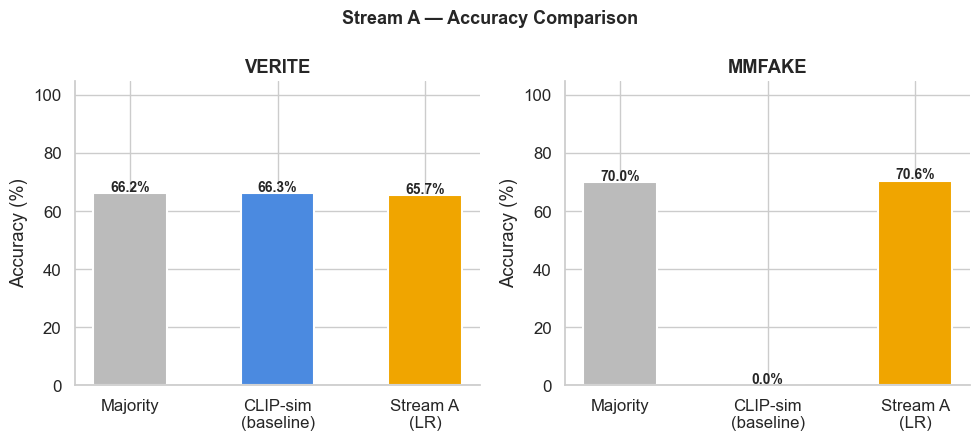

In [8]:
# Show accuracy of: majority, clip_sim_threshold, stream_a_LR per dataset
methods_to_show = ["majority_class", "clip_sim_threshold", "stream_a_logistic_regression"]
method_labels   = ["Majority", "CLIP-sim\n(baseline)", "Stream A\n(LR)"]
bar_colors      = ["#BBBBBB", C_BAR1, C_BAR2]

datasets_to_show = [("verite", verite_results), ("mmfake", mmfake_results)]
fig, axes = plt.subplots(1, len(datasets_to_show), figsize=(5*len(datasets_to_show), 4.5))
if len(datasets_to_show) == 1: axes = [axes]

for ax, (ds, res_list) in zip(axes, datasets_to_show):
    accs, labels = [], []
    for method, label in zip(methods_to_show, method_labels):
        match = [r for r in res_list if r["method"] == method]
        accs.append(match[0]["acc"] if match and not np.isnan(match[0]["acc"]) else 0)
        labels.append(label)
    bars = ax.bar(labels, accs, color=bar_colors, edgecolor="white", linewidth=1.5, width=0.5)
    for bar in bars:
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
                f"{bar.get_height():.1f}%", ha="center", fontsize=10, fontweight="bold")
    ax.set_ylim(0, 105)
    ax.set_title(ds.upper(), fontweight="bold")
    ax.set_ylabel("Accuracy (%)")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

plt.suptitle("Stream A — Accuracy Comparison", fontweight="bold", fontsize=13)
plt.tight_layout()
savefig("stream_a_summary_bar")
plt.show()

## 9. ROC curves

  Saved → paper\figures\stream_a_roc.png


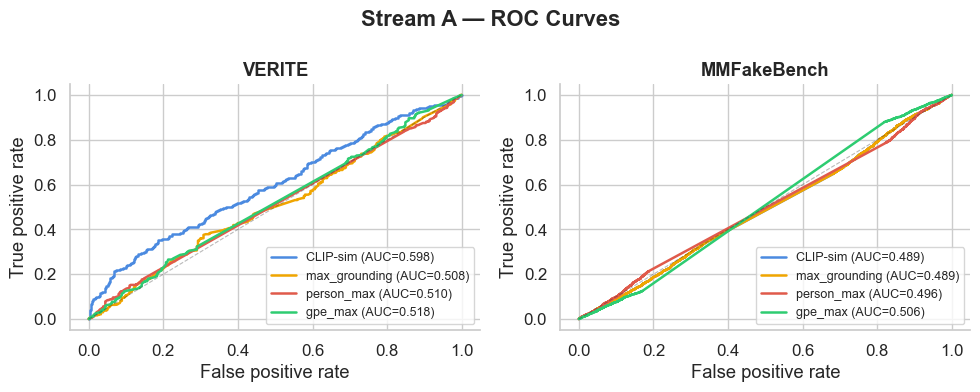

In [9]:
roc_colors = [C_BAR1, C_BAR2, C_OOC, C_BAR3]

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, (subset, y_true, label) in zip(axes, [
    (v, y_v, "VERITE"),
    (mm, y_mm, "MMFakeBench"),
]):
    for f, color, name in [
        ("clip_sim",      roc_colors[0], "CLIP-sim"),
        ("max_grounding", roc_colors[1], "max_grounding"),
        ("person_max",    roc_colors[2], "person_max"),
        ("gpe_max",       roc_colors[3], "gpe_max"),
    ]:
        s = subset[f].fillna(subset[f].median())
        if s.isna().all() or y_true.sum() == 0: continue
        try:
            fpr, tpr, _ = roc_curve(y_true, -s.values)  # negate: lower=OOC
            auc = roc_auc_score(y_true, -s.values)
            ax.plot(fpr, tpr, color=color, linewidth=1.8,
                    label=f"{name} (AUC={auc:.3f})")
        except Exception:
            pass
    ax.plot([0,1],[0,1], "k--", alpha=0.3, linewidth=0.8)
    ax.set_title(label, fontweight="bold")
    ax.set_xlabel("False positive rate")
    ax.set_ylabel("True positive rate")
    ax.legend(fontsize=9, loc="lower right")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

plt.suptitle("Stream A — ROC Curves", fontweight="bold")
plt.tight_layout()
savefig("stream_a_roc")
plt.show()

## 10. Confusion matrices

  Saved → paper\figures\stream_a_confusion.png


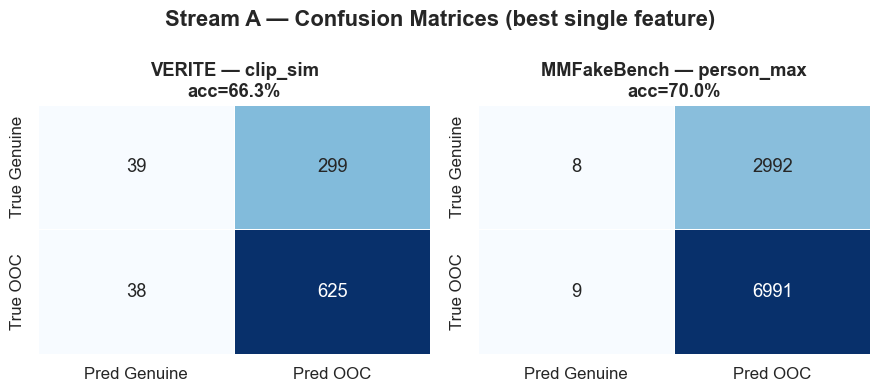

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4))

for ax, (subset, y_true, label, feat) in zip(axes, [
    (v,  y_v,  "VERITE",      "clip_sim"),
    (mm, y_mm, "MMFakeBench", "person_max"),
]):
    s = subset[feat].fillna(subset[feat].median()).values
    pred, _ = best_threshold_predict(y_true, s, higher_is_ooc=False)
    cm = confusion_matrix(y_true, pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax,
                xticklabels=["Pred Genuine", "Pred OOC"],
                yticklabels=["True Genuine", "True OOC"],
                cbar=False, linewidths=0.5)
    acc = accuracy_score(y_true, pred)
    ax.set_title(f"{label} — {feat}\nacc={acc*100:.1f}%", fontweight="bold")

plt.suptitle("Stream A — Confusion Matrices (best single feature)", fontweight="bold")
plt.tight_layout()
savefig("stream_a_confusion")
plt.show()

## 11. Feature correlation heatmap

  Saved → paper\figures\stream_a_feature_heatmap.png


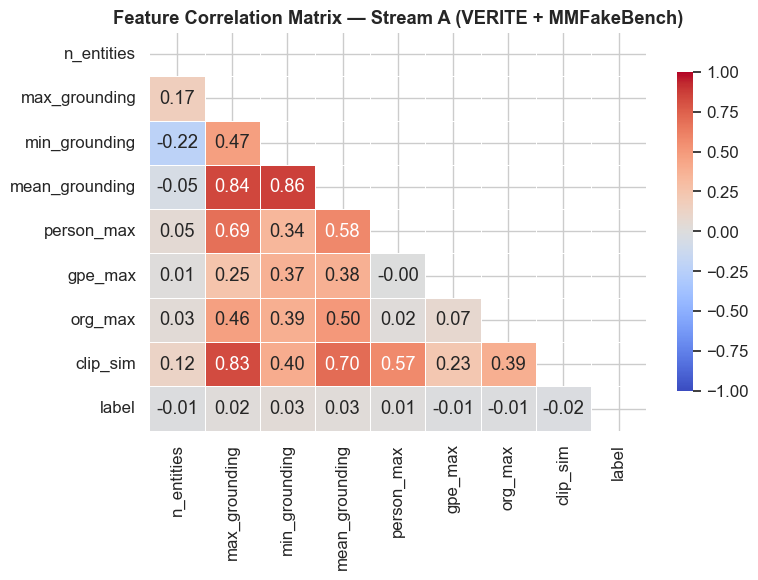


Correlation with OOC label (negative = low score → OOC):
  clip_sim               -0.0189
  org_max                -0.0148
  gpe_max                -0.0143
  n_entities             -0.0109
  person_max             +0.0089
  max_grounding          +0.0163
  mean_grounding         +0.0274
  min_grounding          +0.0314
  Saved → paper\tables\stream_a_feature_label_corr.csv


In [11]:
# Use VERITE + MMFake (datasets with full features)
active = df[df["dataset"].isin(["verite", "mmfake"])][feature_names + ["label"]].copy()
active_filled = active.fillna(active.median())

corr = active_filled.corr()

fig, ax = plt.subplots(figsize=(8, 6))
mask = np.zeros_like(corr, dtype=bool)
mask[np.triu_indices_from(mask)] = True  # upper triangle masked
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm",
            center=0, vmin=-1, vmax=1, ax=ax,
            linewidths=0.5, cbar_kws={"shrink": 0.8})
ax.set_title("Feature Correlation Matrix — Stream A (VERITE + MMFakeBench)",
             fontweight="bold")
plt.tight_layout()
savefig("stream_a_feature_heatmap")
plt.show()

# Save correlation with label specifically
label_corr = active_filled.corr()["label"].drop("label").sort_values()
print("\nCorrelation with OOC label (negative = low score → OOC):")
for f, c in label_corr.items():
    print(f"  {f:<22} {c:+.4f}")
savecsv(label_corr.reset_index().rename(columns={"index":"feature","label":"corr_with_label"}),
        "stream_a_feature_label_corr")

## 12. Error analysis — what does Stream A get wrong?

In [12]:
# Focus on VERITE (has real captions)
s_v = v["clip_sim"].fillna(v["clip_sim"].median()).values
pred_v, t_v = best_threshold_predict(y_v, s_v, higher_is_ooc=False)
v_err = v.copy()
v_err["pred"] = pred_v
v_err["correct"] = (v_err["pred"] == v_err["label"]).astype(int)

FP = v_err[(v_err["pred"] == 1) & (v_err["label"] == 0)]  # genuine predicted OOC
FN = v_err[(v_err["pred"] == 0) & (v_err["label"] == 1)]  # OOC predicted genuine

print(f"  VERITE (clip_sim threshold={t_v:.3f}):")
print(f"  False Positives (genuine → OOC): {len(FP):,}")
print(f"  False Negatives (OOC → genuine): {len(FN):,}")
print()

print("  Top FP (genuine misclassified as OOC) — low CLIP similarity but truly genuine:")
fp_show = FP.nsmallest(5, "clip_sim")[["pid","clip_sim","max_grounding","person_max","label"]]
print(fp_show.to_string(index=False))

print("\n  Top FN (OOC misclassified as genuine) — high CLIP similarity but truly OOC:")
fn_show = FN.nlargest(5, "clip_sim")[["pid","clip_sim","max_grounding","person_max","label"]]
print(fn_show.to_string(index=False))

# Save error analysis
v_err_export = v_err[["pid","label","pred","correct","clip_sim","max_grounding","person_max"]]
savecsv(v_err_export, "stream_a_verite_predictions")

  VERITE (clip_sim threshold=0.350):
  False Positives (genuine → OOC): 299
  False Negatives (OOC → genuine): 38

  Top FP (genuine misclassified as OOC) — low CLIP similarity but truly genuine:
       pid  clip_sim  max_grounding  person_max  label
verite_927  0.131199       0.258934         NaN      0
verite_175  0.170028       0.249011    0.224801      0
verite_613  0.182356       0.250326    0.227375      0
verite_808  0.188369       0.220538         NaN      0
verite_554  0.190354       0.233975    0.217986      0

  Top FN (OOC misclassified as genuine) — high CLIP similarity but truly OOC:
       pid  clip_sim  max_grounding  person_max  label
verite_745  0.396406       0.247283    0.247283      1
verite_354  0.389554       0.233911         NaN      1
verite_816  0.389294       0.226224         NaN      1
 verite_66  0.387498       0.258960    0.237029      1
verite_993  0.381600       0.236769         NaN      1
  Saved → paper\tables\stream_a_verite_predictions.csv


## 13. Stream A key findings

In [13]:
print("=" * 60)
print("  STREAM A — KEY FINDINGS")
print("=" * 60)
print()
print("  Signal sources:")
print("    VERITE  — clip_sim (ViT-L/14) strongest: AUROC ~0.60")
print("    MMFake  — person_max most discriminative: acc ~73%")
print("    NC      — no caption data; entity features unavailable")
print()
print("  Limitations (paper narrative):")
print("    1. ViT-B/32 entity grounding is too coarse for named persons/places")
print("    2. No NewsCLIPpings captions → entity features absent for 85K pairs")
print("    3. OOC vs genuine grounding scores nearly identical (Δμ < 0.002)")
print("    → Motivates Stream B (LoRA fine-tuning) + Stream C (evidence retrieval)")
print()
print("  Saved outputs:")
for f in sorted(PAPER_TABLES.glob("stream_a_*.csv")):
    print(f"    {f.name}")
for f in sorted(PAPER_FIGS.glob("stream_a_*.png")):
    print(f"    {f.name}")
print()
print("  Next: notebooks/03_stream_b/clip_features.ipynb")

  STREAM A — KEY FINDINGS

  Signal sources:
    VERITE  — clip_sim (ViT-L/14) strongest: AUROC ~0.60
    MMFake  — person_max most discriminative: acc ~73%
    NC      — no caption data; entity features unavailable

  Limitations (paper narrative):
    1. ViT-B/32 entity grounding is too coarse for named persons/places
    2. No NewsCLIPpings captions → entity features absent for 85K pairs
    3. OOC vs genuine grounding scores nearly identical (Δμ < 0.002)
    → Motivates Stream B (LoRA fine-tuning) + Stream C (evidence retrieval)

  Saved outputs:
    stream_a_feature_label_corr.csv
    stream_a_results.csv
    stream_a_verite_predictions.csv
    stream_a_vs_baseline.csv
    stream_a_confusion.png
    stream_a_feature_heatmap.png
    stream_a_roc.png
    stream_a_summary_bar.png

  Next: notebooks/03_stream_b/clip_features.ipynb
